<table style="background-color: transparent; width:100%">
    <tr style="background-color: transparent; text-align:center;">
        <td width="100%" align="center"><font size="7" color="#6366F1"><b>Computación Cuántica</b></font></td>
    </tr>
    <tr style="background-color: transparent; text-align:center;">
        <td width="100%"><font size="4" color="black">Temas Selectos de Ingeniería en Computación III</font></td>
    </tr>
    <tr style="background-color: transparent; text-align:center;">
        <td width="100%"><font size="4" color="black">Facultad de Ingeniería, UNAM | Semestre: 2027-1</font></td>
    </tr>
    <tr style="background-color: transparent; text-align:center;">
        <td width="100%"><font size="6" color="#6366F1"><b>Práctica 5: Algoritmos Cuánticos III (Bernstein–Vazirani y Grover)</b></font></td>
    </tr>
</table>

---
* **Alumna:** Karla Beatriz Rojas Chimal
* **No. de Cuenta:** 320048025
* **Carrera:** Ingeniería en Computación
* **Profesora Titular:** Naomi Itzel Reyes Granados
* **Asistente:** González Juárez Sebastián

---
### Contenido del Notebook

1. [Algoritmo de Bernstein–Vazirani](#1)
2. [Algoritmo de Grover](#2)
3. [Extra: Búsqueda en una base de datos mediante Grover en PennyLane](#3)


### Declaración sobre el uso de Inteligencia Artificial (Instrucción C)
De acuerdo con los lineamientos de la práctica, declaro el uso de herramientas de inteligencia artificial en la elaboración de este notebook.

* **Herramienta empleada:** IBM Bob (asistente de IA de programación).
* **Incisos en los que se utilizó:** Estructura general del notebook, código y redacción de las explicaciones de los Ejercicios 1, 2 y del Ejercicio extra.
* **Razón de su uso:** Generar el borrador del notebook siguiendo el formato de las prácticas anteriores y ejecutarlo en un entorno con Qiskit y PennyLane para obtener las salidas. El resultado debe ser revisado por mí antes de la entrega.
* **Prompt principal utilizado:** *"Generar dos notebooks de Práctica 5 (versión PRACTICAENTREGAR y versión resueltoclase) replicando el formato de las prácticas previas y completando los bloques pendientes de Bernstein–Vazirani y Grover del notebook base de Lab 5"* (se anexaron las instrucciones completas de la práctica).


In [1]:
# Instalo todo en silencio, directo en el kernel que estoy usando
%pip install qiskit pennylane matplotlib pylatexenc --quiet

In [2]:
# ==============================================================================
#  /\_/\
# ( o.o )   CONFIGURACIÓN INICIAL: LIBRERÍAS
#  > ^ <
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit.primitives import StatevectorSampler
from qiskit.visualization import plot_histogram
from qiskit.providers.basic_provider import BasicSimulator

# Simulador ideal (sin ruido) para Bernstein–Vazirani
sim = BasicSimulator()
print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


<a id="1"></a>
```
 /\_/\
( o.o )  ¡a trabajar!
 > ^ <
```

# 1. Algoritmo de Bernstein–Vazirani

Se quiere recuperar una cadena secreta $s\in\{0,1\}^6$ a partir de la función

$$f(x)=s\cdot x \pmod 2 ,\qquad U_f:\ |x\rangle|y\rangle\mapsto|x\rangle|y\oplus (s\cdot x)\rangle .$$

Se usan **6 cúbits de entrada** (`q1`,…,`q6`) y un cúbit auxiliar `q0`. Como en Qiskit el cúbit $q_0$ es el menos significativo, el bit más a la izquierda de `s` se asocia a `q6` y el más a la derecha a `q1`; así, la cadena medida se lee **igual** que `s`.

### 1.a) Construcción del oráculo $U_f$
Por cada posición donde `s` vale `1` se aplica una `CNOT` desde el cúbit de entrada correspondiente hacia el auxiliar `q0`:

$$y\oplus (s\cdot x)=y\oplus\bigoplus_{s_i=1}x_i .$$

La función recibe cualquier cadena de 6 bits, sin modificar su implementación.

Circuito del oráculo Uf para s = 101101:


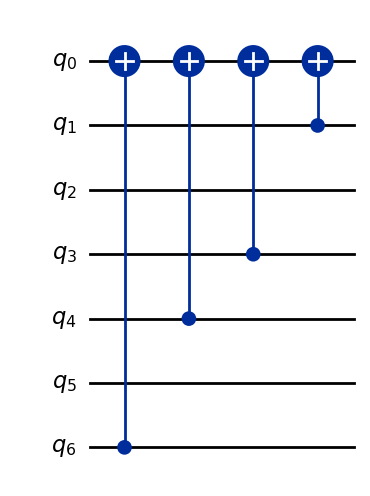

In [3]:
# ==============================================================================
#  /\_/\
# ( o.o )   1.a) BERNSTEIN–VAZIRANI: ORÁCULO Uf
#  > ^ <
# ==============================================================================
N_BV = 6   # longitud de la cadena secreta

def construir_oraculo(s):
    """Oráculo Uf para f(x) = s·x (mod 2). q0 es el auxiliar y q1..q6 son la entrada.
    El bit s[i] (de izquierda a derecha) controla al cúbit q_{n-i}."""
    if len(s) != N_BV or set(s) - {"0", "1"}:
        raise ValueError("s debe ser una cadena binaria de 6 bits")
    uf = QuantumCircuit(N_BV + 1, name="Uf")
    for i, bit in enumerate(s):
        if bit == "1":
            uf.cx(N_BV - i, 0)
    return uf

print("Circuito del oráculo Uf para s = 101101:")
display(construir_oraculo("101101").draw("mpl"))

```
  |\__/,|   (`\
  |_ _  |.--.) )
  ( T   )     /
 (((^_(((/(((_/
```

### 1.b) Implementación del algoritmo
Pasos del circuito (7 cúbits, 6 bits clásicos):

1. **Preparación del auxiliar:** `X` sobre `q0` para obtener $|1\rangle$.
2. **Hadamard:** `H` sobre los 7 cúbits; el auxiliar queda en $|-\rangle$ y la entrada en la superposición uniforme.
3. **Oráculo $U_f$:** por *phase kickback* produce $\frac{1}{\sqrt{2^6}}\sum_x(-1)^{s\cdot x}|x\rangle$.
4. **Hadamard** sobre los 6 cúbits de entrada, que lleva el estado a $|s\rangle$.
5. **Medición** de los 6 cúbits de entrada.

Circuito completo de Bernstein–Vazirani para s = 101101:


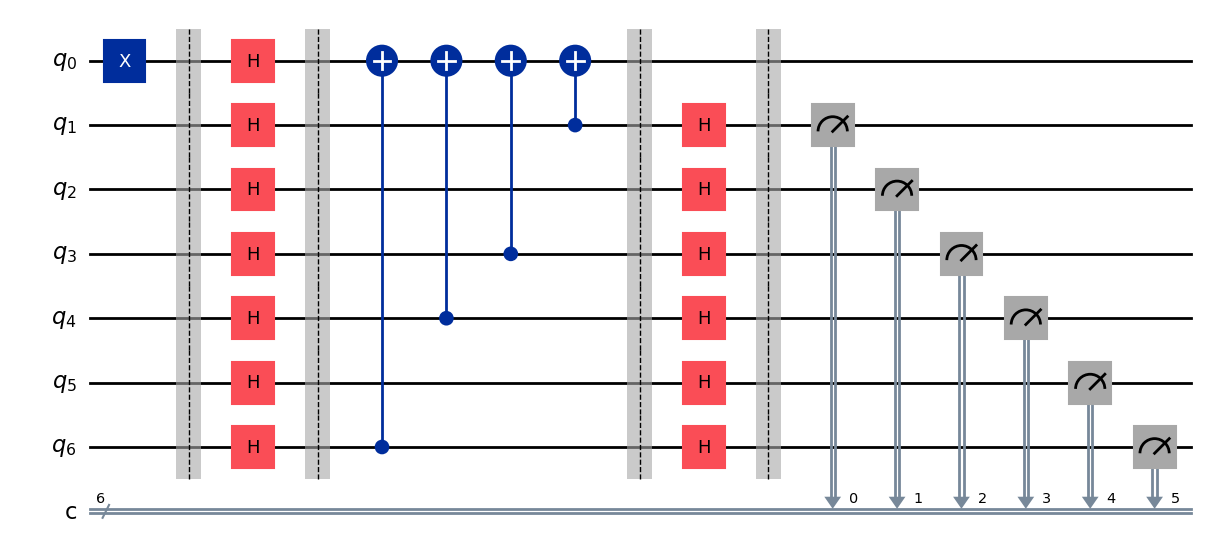

In [4]:
def bernstein_vazirani(s):
    qc = QuantumCircuit(N_BV + 1, N_BV)
    # Paso 1: el auxiliar q0 en |1>
    qc.x(0)
    qc.barrier()
    # Paso 2: Hadamard en todos (el auxiliar queda en |->)
    qc.h(range(N_BV + 1))
    qc.barrier()
    # Paso 3: el oráculo Uf
    qc.compose(construir_oraculo(s), inplace=True)
    qc.barrier()
    # Paso 4: Hadamard solo en los cúbits de entrada
    qc.h(range(1, N_BV + 1))
    qc.barrier()
    # Paso 5: medir los cúbits de entrada (q_{j+1} -> bit clásico j)
    qc.measure(range(1, N_BV + 1), range(N_BV))
    return qc

print("Circuito completo de Bernstein–Vazirani para s = 101101:")
display(bernstein_vazirani("101101").draw("mpl"))

```
      /\_____/\
     /  o   o  \
    ( ==  ^  == )
     )         (
    (           )
   ( (  )   (  ) )
  (__(__)___(__)__)
```

### 1.c) Simulación y resultados
Simulador: **`BasicSimulator`** de Qiskit con 1024 `shots`. Se llama a las **mismas** funciones `construir_oraculo` y `bernstein_vazirani` para las tres cadenas, sin modificarlas entre una corrida y otra.

s = 101101 -> conteos: {'101101': 1024} | cadena recuperada: 101101 | ¿correcta? True


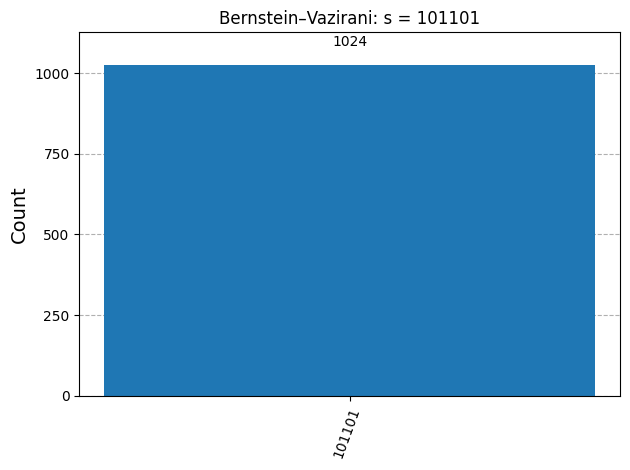

s = 011010 -> conteos: {'011010': 1024} | cadena recuperada: 011010 | ¿correcta? True


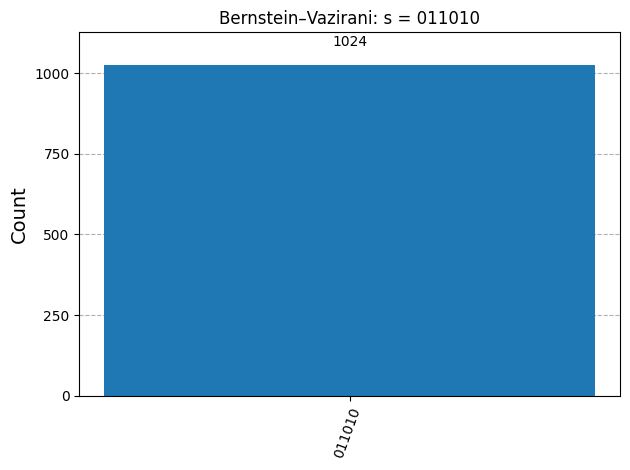

s = 110011 -> conteos: {'110011': 1024} | cadena recuperada: 110011 | ¿correcta? True


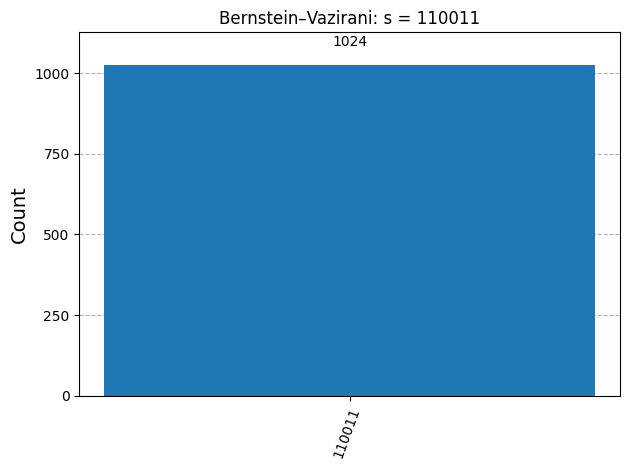

In [5]:
SHOTS = 1024
cadenas = ["101101", "011010", "110011"]

for s in cadenas:
    qc = bernstein_vazirani(s)
    conteos = sim.run(transpile(qc, sim), shots=SHOTS).result().get_counts()
    recuperada = max(conteos, key=conteos.get)
    print(f"s = {s} -> conteos: {conteos} | cadena recuperada: {recuperada} | ¿correcta? {recuperada == s}")
    display(plot_histogram(conteos, title=f"Bernstein–Vazirani: s = {s}"))
    plt.show()

**Conclusión del Ejercicio 1:** para las tres cadenas se mide un único resultado con probabilidad $1$ y coincide exactamente con la cadena secreta (`101101`, `011010` y `110011`). Además, el algoritmo necesita **una sola consulta** al oráculo, mientras que un procedimiento clásico determinista requeriría $n=6$ consultas.

<a id="2"></a>
```
  ∧,,,∧
 (  ̳• · • ̳)
 /    づ♡
```

# 2. Algoritmo de Grover

Se busca en un espacio de $N=2^6=64$ elementos con $M=3$ estados marcados:

$$|001101\rangle,\quad |110010\rangle,\quad |101011\rangle .$$

En las cadenas, el bit más a la izquierda corresponde al cúbit $q_5$ (convención de Qiskit), por lo que el bit en la posición `j` de la cadena actúa sobre el cúbit `q[5-j]`.

### 2.a) Construcción del oráculo
Para cada estado marcado se aplica `X` a los cúbits que valen $0$ en ese estado, de modo que $|\text{marcado}\rangle\mapsto|111111\rangle$; luego una compuerta $Z$ controlada por 5 cúbits (`H`–`MCX`–`H` sobre el último) invierte su fase, y se deshacen las `X`. Así el oráculo aplica $(-1)^{f(x)}$ con $f(x)=1$ solo en los tres estados marcados.

Oráculo de Grover (marca |001101>, |110010> y |101011>):


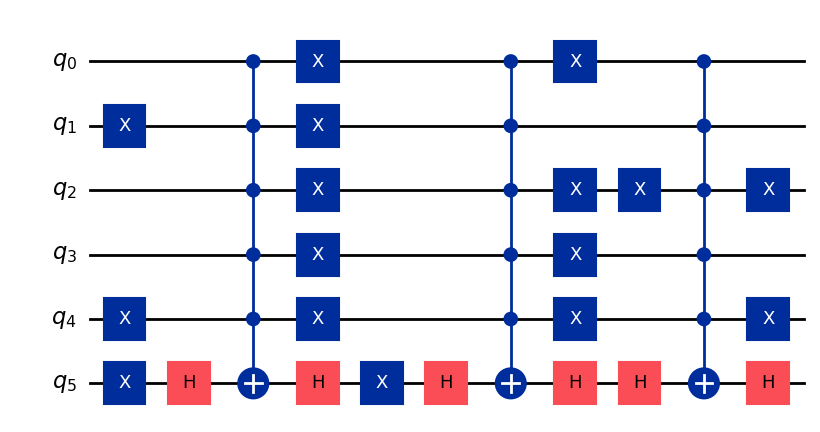

In [6]:
# ==============================================================================
#  /\_/\
# ( o.o )   2.a) GROVER: ORÁCULO
#  > ^ <
# ==============================================================================
N_G = 6
MARCADOS = ["001101", "110010", "101011"]

def oraculo_grover(marcados=MARCADOS, n=N_G):
    """Invierte la fase de cada estado de 'marcados' (cadenas de n bits)."""
    qc = QuantumCircuit(n, name="Oráculo")
    for estado in marcados:
        ceros = [n - 1 - j for j, b in enumerate(estado) if b == "0"]
        if ceros:
            qc.x(ceros)
        # Z multicontrolada sobre |11...1>
        qc.h(n - 1)
        qc.mcx(list(range(n - 1)), n - 1)
        qc.h(n - 1)
        if ceros:
            qc.x(ceros)
    return qc

oraculo = oraculo_grover()
print("Oráculo de Grover (marca |001101>, |110010> y |101011>):")
display(oraculo.draw("mpl", fold=-1))

```
   _._     _,-'""`-._
  (,-.`._,'(       |\`-/|
      `-.-' \ )-`( , o o)
            `-    \`_`"'-
```

### 2.b) Construcción del difusor
El operador de difusión es $D=2|u\rangle\langle u|-I=H^{\otimes 6}(2|\mathbf{0}\rangle\langle\mathbf{0}|-I)H^{\otimes 6}$. El operador $2|\mathbf{0}\rangle\langle\mathbf{0}|-I$ invierte la fase de todos los estados excepto $|0\ldots0\rangle$ y, salvo una fase global, se implementa con `X` en todos los cúbits, una $Z$ multicontrolada y de nuevo `X`:

$$D=H^{\otimes6}\,X^{\otimes6}\,\text{(C}^5\text{Z)}\,X^{\otimes6}\,H^{\otimes6}.$$

Difusor de Grover para 6 cúbits:


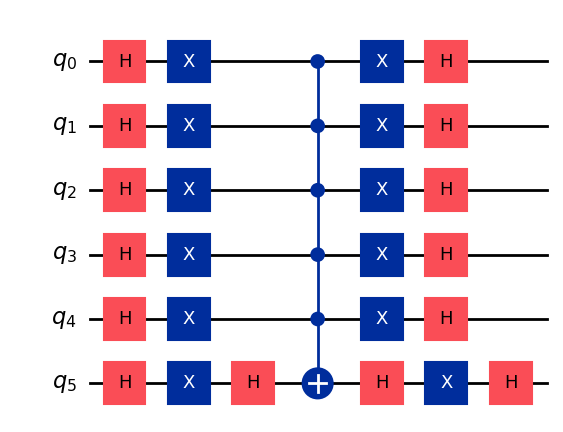

In [7]:
# ==============================================================================
#  /\_/\
# ( o.o )   2.b) GROVER: DIFUSOR
#  > ^ <
# ==============================================================================
def difusor_grover(n=N_G):
    qc = QuantumCircuit(n, name="Difusor")
    qc.h(range(n))
    qc.x(range(n))
    # Z multicontrolada sobre |11...1>
    qc.h(n - 1)
    qc.mcx(list(range(n - 1)), n - 1)
    qc.h(n - 1)
    qc.x(range(n))
    qc.h(range(n))
    return qc

difusor = difusor_grover()
print("Difusor de Grover para 6 cúbits:")
display(difusor.draw("mpl"))

```
  /\_/\
 ( ^.^ )
  > ^ <  miau~
```

### 2.c) Circuito completo, número de iteraciones y simulación
**Número de iteraciones.** Con $N=64$ y $M=3$, la aproximación habitual es

$$k\approx\frac{\pi}{4}\sqrt{\frac{N}{M}}=\frac{\pi}{4}\sqrt{\frac{64}{3}}\approx 3.63 .$$

Como esa fórmula descarta un término $-\tfrac12$, se calcula también el valor exacto. Si $\theta=\arcsin\sqrt{M/N}$, tras $k$ iteraciones la probabilidad de obtener un estado marcado es $\sin^2\big((2k+1)\theta\big)$, que es máxima cuando $(2k+1)\theta\approx\pi/2$, es decir, $k=\frac{\pi}{4\theta}-\frac12$. Se redondea al entero más cercano y se verifica numéricamente con el vector de estado.

theta = 0.2182 rad
k aproximado  (pi/4 * sqrt(N/M))   = 3.628
k exacto      (pi/(4*theta) - 1/2) = 3.099  ->  K = 3


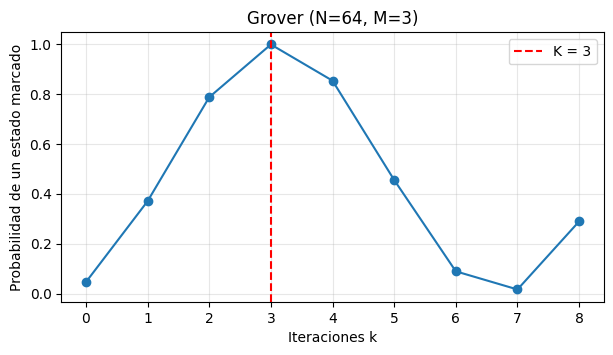

k = 0: 0.0469
k = 1: 0.3708
k = 2: 0.7871
k = 3: 0.9981
k = 4: 0.8531
k = 5: 0.4557
k = 6: 0.0899
k = 7: 0.0173
k = 8: 0.2897


In [8]:
theta = np.arcsin(np.sqrt(len(MARCADOS) / 2**N_G))
k_aprox = np.pi / 4 * np.sqrt(2**N_G / len(MARCADOS))
k_exacto = np.pi / (4 * theta) - 0.5
K = int(round(k_exacto))
print(f"theta = {theta:.4f} rad")
print(f"k aproximado  (pi/4 * sqrt(N/M))   = {k_aprox:.3f}")
print(f"k exacto      (pi/(4*theta) - 1/2) = {k_exacto:.3f}  ->  K = {K}")

def grover_circuito(k, medir=True):
    qc = QuantumCircuit(N_G, N_G if medir else 0)
    qc.h(range(N_G))                         # superposición uniforme
    qc.barrier()
    for _ in range(k):
        qc.append(oraculo_grover().to_gate(label="Oráculo"), range(N_G))
        qc.append(difusor_grover().to_gate(label="Difusor"), range(N_G))
        qc.barrier()
    if medir:
        qc.measure(range(N_G), range(N_G))
    return qc

# Verificación: probabilidad total de los 3 estados marcados para k = 0..8
prob_k = []
for k in range(9):
    probs = Statevector(grover_circuito(k, medir=False)).probabilities_dict()
    prob_k.append(sum(probs.get(m, 0) for m in MARCADOS))

plt.figure(figsize=(7, 3.5))
plt.plot(range(9), prob_k, "o-")
plt.axvline(K, color="red", linestyle="--", label=f"K = {K}")
plt.xlabel("Iteraciones k")
plt.ylabel("Probabilidad de un estado marcado")
plt.title("Grover (N=64, M=3)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
for k, p in enumerate(prob_k):
    print(f"k = {k}: {p:.4f}")

Circuito completo de Grover con K = 3 iteraciones:


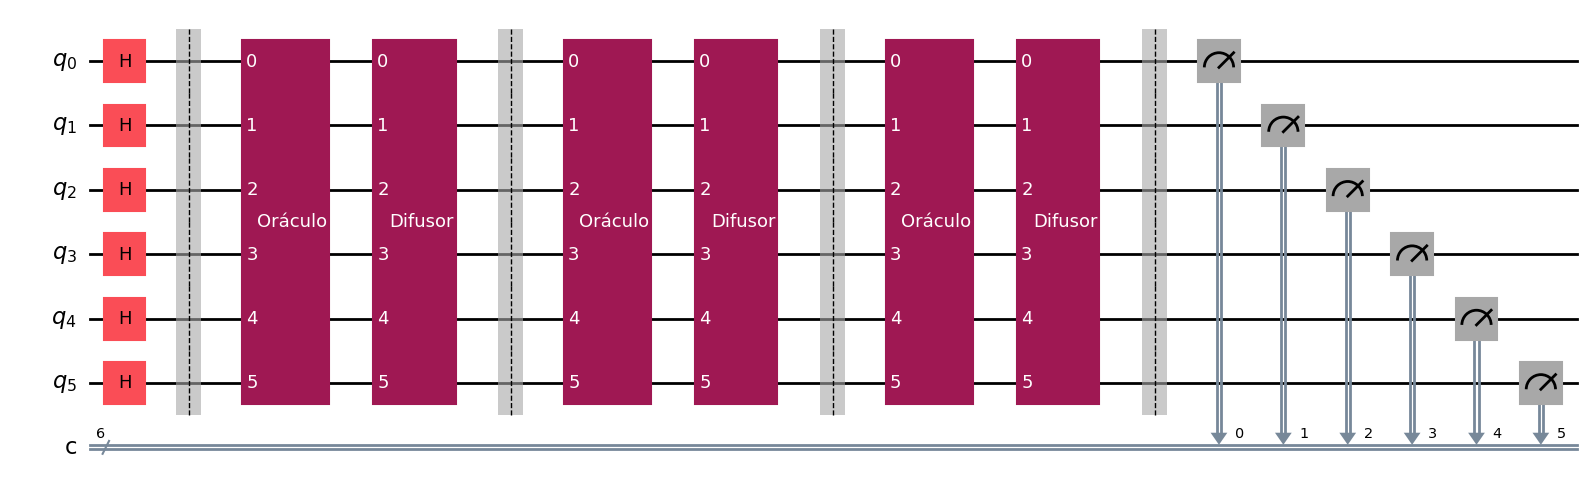

Estados más frecuentes:
|110010>   1389  (0.339)  <- marcado
|101011>   1364  (0.333)  <- marcado
|001101>   1339  (0.327)  <- marcado
|111100>      1  (0.000)
|110001>      1  (0.000)
|010110>      1  (0.000)


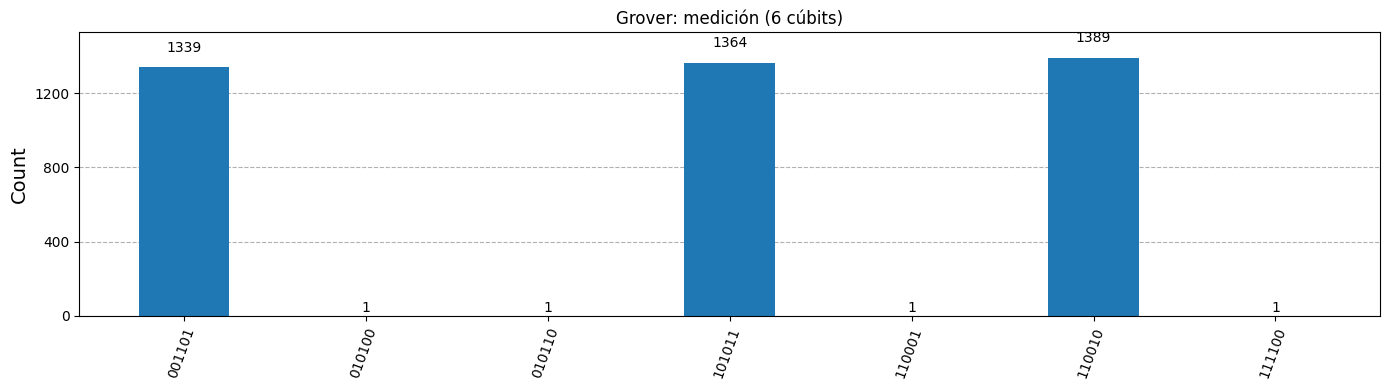

Probabilidad medida de obtener algún estado marcado: 0.999


In [9]:
qc_grover = grover_circuito(K)
print(f"Circuito completo de Grover con K = {K} iteraciones:")
display(qc_grover.draw("mpl"))

SHOTS_G = 4096
sampler = StatevectorSampler()
conteos_g = sampler.run([qc_grover], shots=SHOTS_G).result()[0].data.c.get_counts()

print("Estados más frecuentes:")
for estado, c in sorted(conteos_g.items(), key=lambda kv: -kv[1])[:6]:
    marca = "  <- marcado" if estado in MARCADOS else ""
    print(f"|{estado}>  {c:5d}  ({c / SHOTS_G:.3f}){marca}")

display(plot_histogram(conteos_g, figsize=(14, 4), title="Grover: medición (6 cúbits)"))
plt.show()

exito = sum(conteos_g.get(m, 0) for m in MARCADOS) / SHOTS_G
print(f"Probabilidad medida de obtener algún estado marcado: {exito:.3f}")

**Conclusión del Ejercicio 2:** con $K=3$ iteraciones la probabilidad de medir un estado marcado es cercana al $99.8\,\%$, repartida casi por igual entre $|001101\rangle$, $|110010\rangle$ y $|101011\rangle$ (≈ 1/3 cada uno). Los 61 estados restantes casi desaparecen. Con $K=4$ (el redondeo de la fórmula aproximada) la probabilidad ya baja, porque el algoritmo empieza a **sobre-rotar**, de modo que conviene detenerse en $K=3$.

<a id="3"></a>
```
  /\_/\
 ( ^.^ )
  > ^ <  miau~
```

# 3. Extra: Búsqueda en una base de datos mediante Grover en PennyLane

La base de datos tiene $N=16$ equipos identificados con 4 bits. El oráculo se construye **a partir de los datos**: se recorre el diccionario y, para cada equipo con estado `Disponible`, se invierte la fase de su identificador con `qml.FlipSign`. No se escriben a mano los identificadores. El difusor se arma con `H`, `X`, una $Z$ multicontrolada, `X` y `H`.

En PennyLane, el cable 0 corresponde al bit más a la izquierda, por lo que el índice de las probabilidades coincide con la lectura habitual del identificador.

N = 16, M = 2, pi/4*sqrt(N/M) = 2.221, k exacto = 1.673 -> k = 2


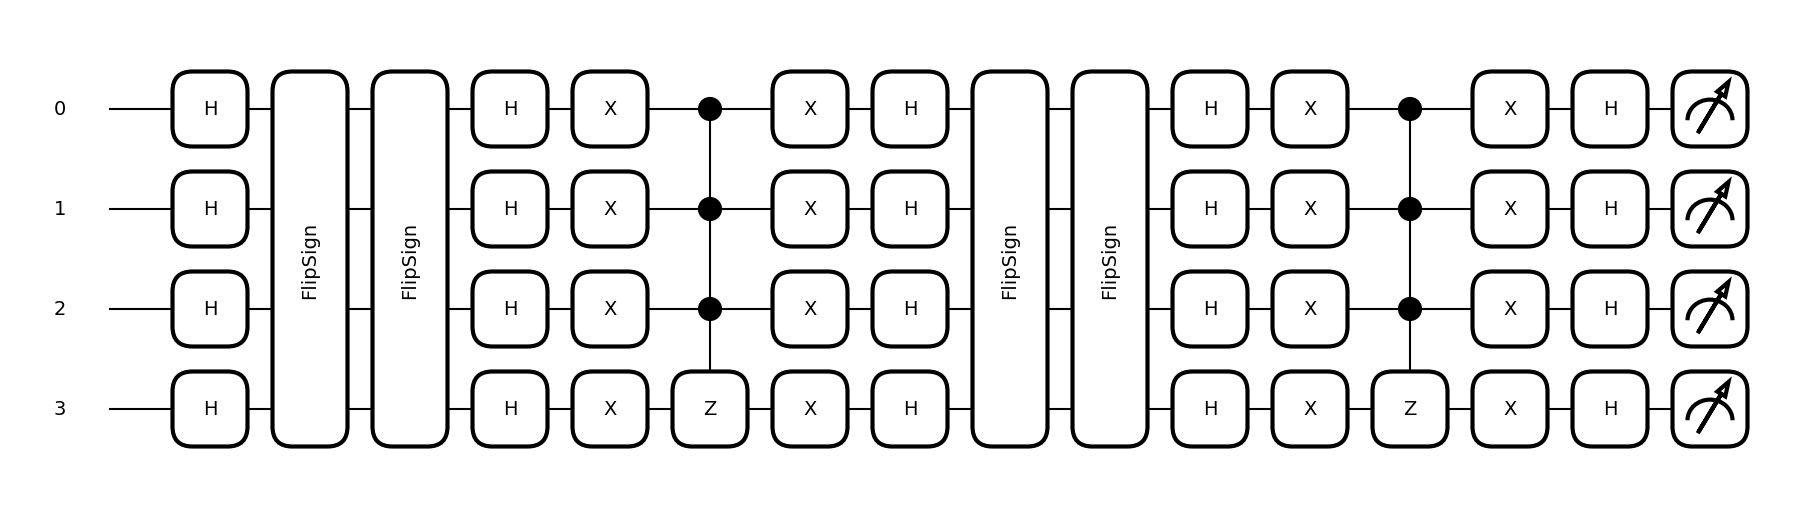

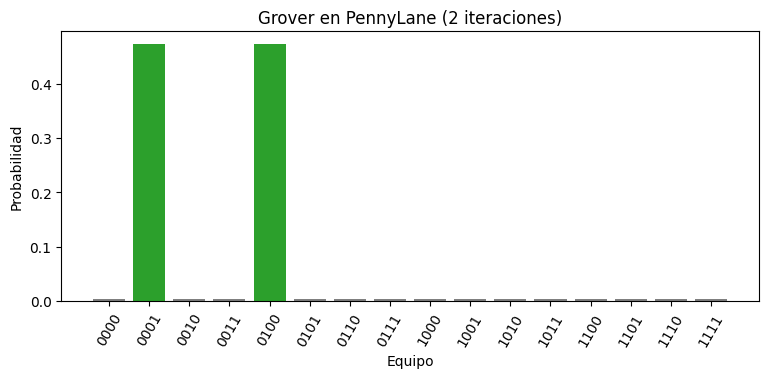

Equipos con mayor probabilidad de medición:
  equipo 0100  P = 0.4727  (Disponible)
  equipo 0001  P = 0.4727  (Disponible)


In [10]:
# ==============================================================================
#  /\_/\
# ( o.o )   EXTRA: GROVER EN PENNYLANE
#  > ^ <
# ==============================================================================
import pennylane as qml

equipos = {
    "0000": "Ocupado",
    "0001": "Disponible",
    "0010": "Ocupado",
    "0011": "Ocupado",
    "0100": "Disponible",
    "0101": "Ocupado",
    "0110": "Ocupado",
    "0111": "Ocupado",
    "1000": "Ocupado",
    "1001": "Ocupado",
    "1010": "Ocupado",
    "1011": "Ocupado",
    "1100": "Ocupado",
    "1101": "Ocupado",
    "1110": "Ocupado",
    "1111": "Ocupado"
}

n_pl = 4
wires = list(range(n_pl))
dev_pl = qml.device("default.qubit", wires=n_pl)

# El oráculo sale de los datos: se marcan los registros con estado "Disponible"
disponibles = [eid for eid, estado in equipos.items() if estado == "Disponible"]
N_pl, M_pl = len(equipos), len(disponibles)

def oraculo_pl():
    for eid in disponibles:
        qml.FlipSign([int(b) for b in eid], wires=wires)

def difusor_pl():
    for w in wires:
        qml.Hadamard(wires=w)
    for w in wires:
        qml.PauliX(wires=w)
    qml.ctrl(qml.PauliZ, control=wires[:-1])(wires=wires[-1])
    for w in wires:
        qml.PauliX(wires=w)
    for w in wires:
        qml.Hadamard(wires=w)

# Número de iteraciones: k = round(pi/(4*theta) - 1/2), theta = asin(sqrt(M/N))
theta_pl = np.arcsin(np.sqrt(M_pl / N_pl))
k_pl = int(round(np.pi / (4 * theta_pl) - 0.5))
print(f"N = {N_pl}, M = {M_pl}, pi/4*sqrt(N/M) = {np.pi / 4 * np.sqrt(N_pl / M_pl):.3f}, "
      f"k exacto = {np.pi / (4 * theta_pl) - 0.5:.3f} -> k = {k_pl}")

@qml.qnode(dev_pl)
def grover_pl():
    for w in wires:
        qml.Hadamard(wires=w)
    for _ in range(k_pl):
        oraculo_pl()
        difusor_pl()
    return qml.probs(wires=wires)

fig, ax = qml.draw_mpl(grover_pl, decimals=None)()
plt.show()

probs_pl = grover_pl()
etiquetas = [f"{i:04b}" for i in range(N_pl)]

plt.figure(figsize=(9, 3.5))
colores = ["tab:green" if e in disponibles else "tab:gray" for e in etiquetas]
plt.bar(etiquetas, probs_pl, color=colores)
plt.xlabel("Equipo")
plt.ylabel("Probabilidad")
plt.title(f"Grover en PennyLane ({k_pl} iteraciones)")
plt.xticks(rotation=60)
plt.show()

print("Equipos con mayor probabilidad de medición:")
for i in np.argsort(probs_pl)[::-1][:M_pl]:
    print(f"  equipo {etiquetas[i]}  P = {probs_pl[i]:.4f}  ({equipos[etiquetas[i]]})")

**Conclusión:** el oráculo marcó los equipos disponibles leyendo el diccionario, sin escribir sus identificadores. Con $k=2$ iteraciones, los dos equipos con mayor probabilidad son `0001` y `0100`, cada uno con ≈ 47 %, que son precisamente los equipos `Disponible`. En total, un equipo disponible se obtiene con ≈ 94.5 % de probabilidad.